In [3]:
import pandas as pd
import numpy as np

In [4]:
df = pd.read_csv("/Users/kshitijsharma/Old Documents/College/Surbhi ma'am work/Final work/Feature Extraction/combined_features.csv")
df.head()

,Image_Index,Class_Label,Combined_Features
0,0,Kidney - normal,"[np.float64(-0.9011194286552345), np.float64(-..."
1,1,Kidney - normal,"[np.float64(-0.29311151800964436), np.float64(..."
2,2,Kidney - normal,"[np.float64(-0.5056150556814429), np.float64(-..."
3,3,Kidney - normal,"[np.float64(-0.6383901554374929), np.float64(-..."
4,4,Kidney - normal,"[np.float64(-1.0114290989341512), np.float64(-..."


In [5]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from tqdm import tqdm
from concurrent.futures import ThreadPoolExecutor

# Parse the standardized features
df['Combined_Features'] = df['Combined_Features'].apply(eval)

# Convert features to NumPy array
X = np.array(df['Combined_Features'].tolist())
y = df['Class_Label'].values

In [6]:

# Define the objective function for feature selection
def objective_function(mask):
    selected_features = np.where(mask > 0.5)[0]
    if len(selected_features) == 0:
        return 1.0  # Penalize empty feature subsets
    X_selected = X[:, selected_features]
    X_train, X_test, y_train, y_test = train_test_split(X_selected, y, test_size=0.3, random_state=42)
    clf = RandomForestClassifier()
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    accuracy = accuracy_score(y_test, y_pred)
    return 1 - accuracy  # Minimize the inverse of accuracy


In [7]:

# Reinforced Lyrebird Optimization Algorithm
class ReinforcedLyrebirdOptimizer:
    def __init__(self, obj_func, dim, bounds, max_iter, population_size, n_jobs=4):
        self.obj_func = obj_func
        self.dim = dim
        self.bounds = bounds
        self.max_iter = max_iter
        self.population_size = population_size
        self.n_jobs = n_jobs
        self.population = np.random.uniform(bounds[0], bounds[1], (population_size, dim))
        self.fitness = np.zeros(population_size)
        self.best_solution = None
        self.best_fitness = float('inf')
        self.elite_fraction = 0.1

    def evaluate_population(self):
        with ThreadPoolExecutor(max_workers=self.n_jobs) as executor:
            self.fitness = np.array(list(executor.map(self.obj_func, self.population)))

    def adapt_phase(self, iter_num):
        return np.random.rand() < (1 - iter_num / self.max_iter)

    def mutate(self, ind):
        if np.random.rand() < 0.1:
            return ind + np.random.normal(0, 0.05, self.dim)
        return ind

    def update_position(self, ind, iter_num):
        if self.adapt_phase(iter_num):
            return ind + np.random.uniform(-1, 1, self.dim) * (1 - iter_num / self.max_iter)
        else:
            momentum = 0.9 * (ind - self.best_solution)
            return ind + np.random.normal(0, 0.1, self.dim) + momentum

    def preserve_elite(self):
        elite_size = int(self.population_size * self.elite_fraction)
        elite_indices = np.argsort(self.fitness)[:elite_size]
        return self.population[elite_indices]

    def optimize(self):
        self.evaluate_population()
        best_idx = np.argmin(self.fitness)
        self.best_solution = self.population[best_idx]
        self.best_fitness = self.fitness[best_idx]

        for iter_num in tqdm(range(self.max_iter), desc="Reinforced Optimizing"):
            elite = self.preserve_elite()
            for i in range(self.population_size):
                new_pos = self.update_position(self.population[i], iter_num)
                new_pos = self.mutate(np.clip(new_pos, self.bounds[0], self.bounds[1]))
                self.population[i] = new_pos

            self.evaluate_population()
            best_idx = np.argmin(self.fitness)
            if self.fitness[best_idx] < self.best_fitness:
                self.best_solution = self.population[best_idx]
                self.best_fitness = self.fitness[best_idx]

            self.population[:len(elite)] = elite

        return self.best_solution, self.best_fitness

In [8]:

# Set optimizer parameters
dim = X.shape[1]
bounds = [0, 1]
max_iter = 100
population_size = 20
n_jobs = 8


In [9]:

# Run RLO optimizer
rlo = ReinforcedLyrebirdOptimizer(objective_function, dim, bounds, max_iter, population_size, n_jobs=n_jobs)
best_mask, best_fitness = rlo.optimize()


Reinforced Optimizing: 100%|██████████| 100/100 [02:52<00:00,  1.72s/it]


In [10]:
# Feature selection mask (BoW-style)
selected_features = np.where(best_mask > 0.5)[0]
print(f"Selected {len(selected_features)} features out of {dim}")
np.save("selected_feature_mask.npy", best_mask > 0.5)

# Apply selected features to DataFrame
df['Selected_Features'] = df['Combined_Features'].apply(lambda x: [x[i] for i in selected_features])

# Save results
df[['Image_Index', 'Class_Label', 'Selected_Features']].to_csv('Reinforced_Lyrebird_selected_features.csv', index=False)

Selected 79 features out of 199


In [42]:
# weighted
class WeightedFeatureRepresentation(nn.Module):
    def __init__(self, input_dim, hidden_dim=64):
        super().__init__()
        self.weight_mlp = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, input_dim),
            nn.Sigmoid()
        )
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, hidden_dim)
        )

    def forward(self, x):
        weights = self.weight_mlp(x)
        x_weighted = x * weights
        return self.encoder(x_weighted)


class Classifier(nn.Module):
    def __init__(self, in_dim, num_classes):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Linear(in_dim, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        return self.fc(x)

repr_model = WeightedFeatureRepresentation(input_dim=input_dim)
clf_model = Classifier(in_dim=64, num_classes=num_classes)

params = list(repr_model.parameters()) + list(clf_model.parameters())
optimizer = torch.optim.Adam(params, lr=1e-3)
criterion = nn.CrossEntropyLoss()

for epoch in range(20):
    repr_model.train()
    clf_model.train()
    optimizer.zero_grad()

    x_repr = repr_model(X_train_t)
    logits = clf_model(x_repr)
    loss = criterion(logits, y_train_t)
    loss.backward()
    optimizer.step()

# Evaluation
repr_model.eval()
clf_model.eval()
with torch.no_grad():
    X_train_feat = repr_model(X_train_t)
    X_test_feat = repr_model(X_test_t)

rf = RandomForestClassifier()
rf.fit(X_train_feat.numpy(), y_train_t.numpy())
y_pred_weighted = rf.predict(X_test_feat.numpy())
acc_weighted = accuracy_score(y_test_t.numpy(), y_pred_weighted)
print(f"WeightedMLP Accuracy: {acc_weighted:.4f}")


WeightedMLP Accuracy: 0.8201


In [44]:
#baseline

class BaselineMLP(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        return self.model(x)

baseline_model = BaselineMLP(input_dim=input_dim, num_classes=num_classes)
optimizer = torch.optim.Adam(baseline_model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

for epoch in range(20):
    baseline_model.train()
    optimizer.zero_grad()
    logits = baseline_model(X_train_t)
    loss = criterion(logits, y_train_t)
    loss.backward()
    optimizer.step()

# Evaluation
baseline_model.eval()
with torch.no_grad():
    train_feat = baseline_model(X_train_t)
    test_feat = baseline_model(X_test_t)

rf_base = RandomForestClassifier()
rf_base.fit(train_feat.numpy(), y_train_t.numpy())
y_pred_base = rf_base.predict(test_feat.numpy())
acc_baseline = accuracy_score(y_test_t.numpy(), y_pred_base)
print(f"BaselineMLP Accuracy: {acc_baseline:.4f}")


BaselineMLP Accuracy: 0.8166


Feature repr. DCFR-NET modified

Replace U-Net with a Residual-style backbone.

Replace coordinate-based INRs with attention-aware INRs.

Use positional encodings with learnable frequency basis for better feature flexibility.

Fuse MIFA + SFFI into a unified “Multi-Domain Attention” module.


Simplify the diffusion process (fixed variance schedule, fewer timesteps).


In [28]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score
from sklearn.ensemble import RandomForestClassifier

# Assume: X_selected_final (NumPy) and y_array (non-numeric) already exist
# Encode labels
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y_array)

# Convert to tensors
X_tensor = torch.tensor(X_selected_final, dtype=torch.float32)
y_tensor = torch.tensor(y_encoded, dtype=torch.long)

# Split data
X_train_t, X_test_t, y_train_t, y_test_t = train_test_split(X_tensor, y_tensor, test_size=0.3, random_state=42)

# Define improved DCFR-Net+ components
class PositionalEncoding(nn.Module):
    def __init__(self, dim, num_freqs=10):
        super().__init__()
        self.freq_bands = 2 ** torch.linspace(0, num_freqs - 1, num_freqs)

    def forward(self, coords):
        out = [coords]
        for freq in self.freq_bands:
            out.append(torch.sin(freq * coords))
            out.append(torch.cos(freq * coords))
        return torch.cat(out, dim=-1)


class ResEncoder(nn.Module):
    def __init__(self, in_channels, out_dim):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(in_channels, 64),
            nn.ReLU(),
            nn.Linear(64, out_dim)
        )

    def forward(self, x):
        return self.model(x)


class DCFRNetPlus(nn.Module):
    def __init__(self, input_dim, num_classes):
        super().__init__()
        self.encoder = ResEncoder(input_dim, 64)
        self.classifier = nn.Sequential(
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        features = self.encoder(x)
        return self.classifier(features), features

# Initialize model
input_dim = X_selected_final.shape[1]
num_classes = len(np.unique(y_encoded))

model = DCFRNetPlus(input_dim=input_dim, num_classes=num_classes)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.CrossEntropyLoss()

# Training loop
epochs = 20
for epoch in range(epochs):
    model.train()
    optimizer.zero_grad()

    logits, _ = model(X_train_t)
    loss = criterion(logits, y_train_t)

    loss.backward()
    optimizer.step()
    print(f"Epoch {epoch+1}/{epochs} - Loss: {loss.item():.4f}")

# Evaluation using RandomForest on learned features
model.eval()
with torch.no_grad():
    _, train_features = model(X_train_t)
    _, test_features = model(X_test_t)

clf = RandomForestClassifier()
clf.fit(train_features.numpy(), y_train_t.numpy())
y_pred = clf.predict(test_features.numpy())
acc = accuracy_score(y_test_t.numpy(), y_pred)
print(f"✅ Accuracy using DCFRNetPlus features + RandomForest: {acc:.4f}")

Epoch 1/20 - Loss: 1.7933
Epoch 2/20 - Loss: 1.7662
Epoch 3/20 - Loss: 1.7400
Epoch 4/20 - Loss: 1.7136
Epoch 5/20 - Loss: 1.6862
Epoch 6/20 - Loss: 1.6575
Epoch 7/20 - Loss: 1.6269
Epoch 8/20 - Loss: 1.5940
Epoch 9/20 - Loss: 1.5588
Epoch 10/20 - Loss: 1.5216
Epoch 11/20 - Loss: 1.4831
Epoch 12/20 - Loss: 1.4440
Epoch 13/20 - Loss: 1.4052
Epoch 14/20 - Loss: 1.3675
Epoch 15/20 - Loss: 1.3313
Epoch 16/20 - Loss: 1.2966
Epoch 17/20 - Loss: 1.2634
Epoch 18/20 - Loss: 1.2313
Epoch 19/20 - Loss: 1.2000
Epoch 20/20 - Loss: 1.1693
✅ Accuracy using DCFRNetPlus features + RandomForest: 0.8720


In [26]:
# t-SNE visualization of latent features

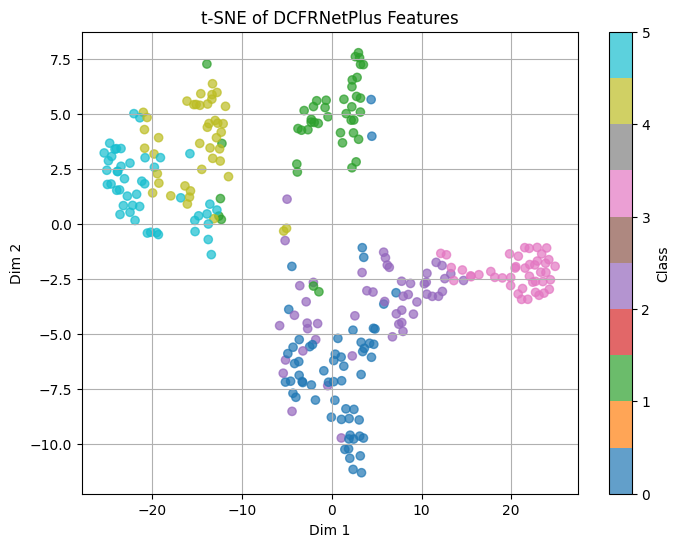

In [27]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

# Extract features
model.eval()
with torch.no_grad():
    _, train_features = model(X_train_t)
    _, test_features = model(X_test_t)

# Use t-SNE to project to 2D
tsne = TSNE(n_components=2, random_state=42)
features_2d = tsne.fit_transform(test_features.numpy())

# Plot t-SNE
plt.figure(figsize=(8, 6))
scatter = plt.scatter(features_2d[:, 0], features_2d[:, 1], c=y_test_t.numpy(), cmap='tab10', alpha=0.7)
plt.title('t-SNE of DCFRNetPlus Features')
plt.xlabel('Dim 1')
plt.ylabel('Dim 2')
plt.colorbar(scatter, label='Class')
plt.grid(True)
plt.show()

### Kruskal–Wallis H-test and Friedman test

In [45]:
acc_dcfr = [0.8651, 0.8720, 0.8684]
acc_weighted = [0.8512, 0.8201, 0.8270]
acc_baseline = [0.8028, 0.7716, 0.8166]

In [47]:
from scipy.stats import friedmanchisquare

stat, p = friedmanchisquare(acc_dcfr, acc_weighted, acc_baseline)
print(f"Friedman test: chi2={stat:.4f}, p={p:.4f}")

if p < 0.05:
    print("Significant differences exist between models")
else:
    print("No significant difference between models.")

Friedman test: chi2=6.0000, p=0.0498
Significant differences exist between models


In [48]:
from scipy.stats import kruskal

stat, p = kruskal(acc_dcfr, acc_weighted, acc_baseline)
print(f"Kruskal–Wallis H-test: H={stat:.4f}, p={p:.4f}")

if p < 0.05:
    print("Significant differences exist between models.")
else:
    print("No significant difference between models.")

Kruskal–Wallis H-test: H=7.2000, p=0.0273
Significant differences exist between models.
